In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pred = pd.read_csv(
    "../data/processed/xgboost_predictions.csv",
    parse_dates=["Date"]
)

print("Shape:", pred.shape)
print("Columns:", pred.columns.tolist())
display(pred.head())

Shape: (162796, 4)
Columns: ['Date', 'Store', 'Sales', 'XGBoost_Prediction']


,Date,Store,Sales,XGBoost_Prediction
0,2015-02-06,1,5022,4994.4490
1,2015-02-06,2,5260,5534.5107
2,2015-02-06,3,7920,7222.4210
3,2015-02-06,4,10985,10423.4840
4,2015-02-06,5,5209,5191.5444


In [2]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

actual = pred["Sales"]
predicted = pred["XGBoost_Prediction"]

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

print(f"Overall MAE: {mae:.2f}")
print(f"Overall RMSE: {rmse:.2f}")

pred["Error"] = actual - predicted
pred["Absolute_Error"] = pred["Error"].abs()

print(f"Mean Error (Bias): {pred['Error'].mean():.2f}")

Overall MAE: 697.11
Overall RMSE: 999.25
Mean Error (Bias): 3.15


In [3]:
store_errors = (
    pred.groupby("Store")
    .agg(
        Actual_Mean=("Sales", "mean"),
        MAE=("Absolute_Error", "mean"),
        Mean_Error=("Error", "mean"),
        Observations=("Sales", "size")
    )
    .reset_index()
    .sort_values("MAE", ascending=False)
)

display(store_errors.head(10))

,Store,Actual_Mean,MAE,Mean_Error,Observations
841,842,19944.137931,2239.876503,297.725621,145
643,644,9936.219512,2166.792143,191.807403,123
875,876,9626.901515,1848.067245,-103.548878,132
908,909,11790.809160,1735.464063,332.976269,131
816,817,20377.835616,1727.314161,-694.501839,146
1113,1114,22193.801370,1671.319705,1205.953075,146
191,192,13034.600000,1636.133597,492.022066,145
826,827,14920.075342,1635.985942,252.194147,146
962,963,11035.724138,1554.343491,-402.387312,145
420,421,9788.232877,1548.649181,363.908722,146


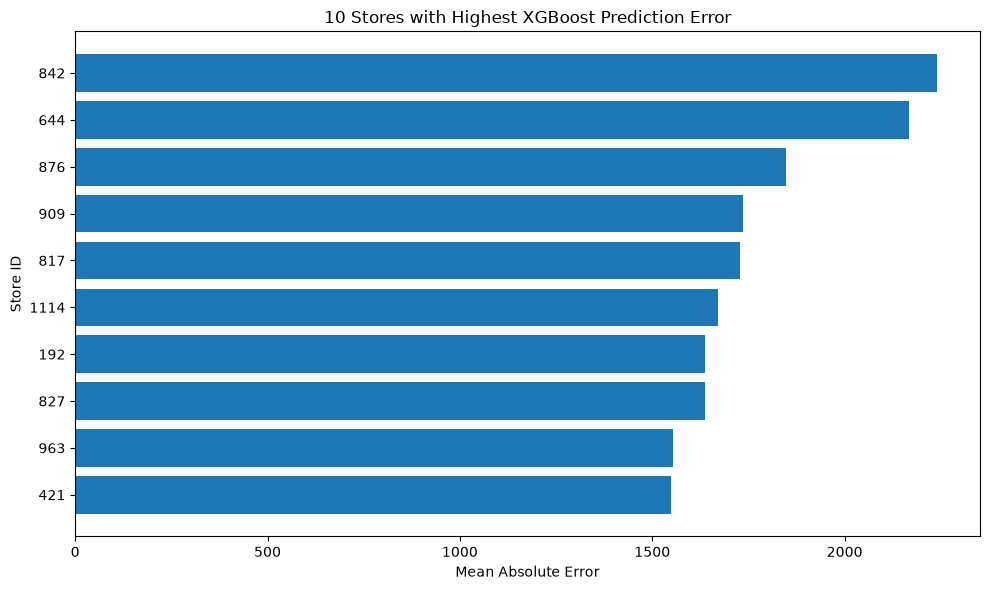

In [4]:
worst10 = store_errors.head(10).sort_values("MAE")

plt.figure(figsize=(10, 6))
plt.barh(
    worst10["Store"].astype(str),
    worst10["MAE"]
)
plt.xlabel("Mean Absolute Error")
plt.ylabel("Store ID")
plt.title("10 Stores with Highest XGBoost Prediction Error")
plt.tight_layout()
plt.show()

In [5]:
from pathlib import Path

print("Notebook folder:", Path.cwd())
print(
    "Possible feature importance files:",
    list(Path("../data/processed").glob("*importance*.csv"))
)

Notebook folder: C:\Users\Shrey\OneDrive\Desktop\stocksense\notebooks
Possible feature importance files: []


In [6]:
# Check whether prediction errors are concentrated in a few stores
store_errors["Error_Rate"] = (
    store_errors["MAE"] / store_errors["Actual_Mean"].abs()
) * 100

display(
    store_errors[
        ["Store", "Actual_Mean", "MAE", "Error_Rate", "Observations"]
    ].sort_values("Error_Rate", ascending=False).head(10)
)

,Store,Actual_Mean,MAE,Error_Rate,Observations
643,644,9936.219512,2166.792143,21.807008,123
182,183,5473.813433,1066.152297,19.477323,134
875,876,9626.901515,1848.067245,19.196906,132
674,675,3822.544828,716.252212,18.737575,145
467,468,5918.239726,1093.985243,18.484977,146
298,299,6660.840237,1217.456292,18.277819,169
896,897,3377.448276,615.041479,18.210241,145
552,553,7472.841379,1335.847359,17.876030,145
529,530,5060.052632,842.876497,16.657465,171
266,267,9115.082192,1500.251325,16.458999,146


### Day 13 — XGBoost Error Analysis

- Evaluated XGBoost predictions across 162,796 rows.
- Overall MAE was 697.11 and RMSE was 999.25.
- Mean error (Actual − Predicted) was +3.15, indicating very small average underprediction.
- Store-wise analysis identified Store 842 and Store 644 as the highest-error stores, with MAEs of approximately 2239.88 and 2166.79.
- The error distribution varies by store, so overall metrics alone do not describe performance for every store.
- Further feature-importance analysis is needed to understand which input features contribute most to the model's predictions.